## Grading Rubric

- **Part 1: Autoencoder Implementation and Training** — **25 points**
- **Part 2: Autoencoder with Classifier Head** — **25 points**
- **Part 3: Conceptual Questions** — **10 points**
- **Part 5: Advanced Autoencoder (hard mode)** — **20 points**
- **Part 6A: Skip-gram Word2Vec with Full Softmax** — **10 points**
- **Part 6B: Skip-gram Word2Vec with Negative Sampling** — **10 points**

**Core total: 100 points**

### Extra Credit
- **Part 4: Another twist to the autoencoder** — **+10 points**

### Submission expectation
- For coding parts, points are split across: correctness, code clarity, and brief result discussion.
- For question parts, points are split across: conceptual correctness, depth, and clarity.


## HW2: Autoencoder From Scratch in PyTorch

### Part 1: Autoencoder Implementation and Training (25 points)

An autoencoder is a type of artificial neural network used to learn efficient codings of unlabeled data (unsupervised learning). The aim of an autoencoder is to learn a representation (encoding) for a set of data, typically for the purpose of dimensionality reduction. Along with the reduction side, a reconstructing side is also learned, where the autoencoder tries to generate from the reduced encoding a representation as close as possible to its original input, hence its name.

It looks like this:

``` 
Input Layer --> Encoder --> Latent Space --> Decoder --> Output Layer
```

Where:
- **Input Layer**: The original data that we want to compress.
- **Encoder**: The part of the network that compresses the input data into a lower-dimensional representation (latent space).
- **Latent Space**: The compressed representation of the input data.
- **Decoder**: The part of the network that reconstructs the original data from the compressed representation.
- **Output Layer**: The reconstructed data that should be as close as possible to the original input.

Mathematically, an autoencoder consists of two main functions:
1. **Encoder Function**: \( h = f(x) \)
   - Where \( x \) is the input data, \( f \) is the encoder function, and \( h \) is the latent representation.
2. **Decoder Function**: \( r = g(h) \)
   - Where \( h \) is the latent representation, \( g \) is the decoder function, and \( r \) is the reconstructed output.

In this homework, you will implement a simple autoencoder using PyTorch. The autoencoder will be trained on the MNIST dataset, which consists of handwritten digits.

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST

In [4]:
dataset = MNIST(root='./data', train=True, download=True, transform=transforms.ToTensor())
dataloader = DataLoader(dataset, batch_size=64, shuffle=True)
validation_dataset = MNIST(root='./data', train=False, download=True, transform=transforms.ToTensor())
validation_dataloader = DataLoader(validation_dataset, batch_size=64, shuffle=False)


100%|██████████| 9.91M/9.91M [00:12<00:00, 805kB/s] 
100%|██████████| 28.9k/28.9k [00:00<00:00, 102kB/s]
100%|██████████| 1.65M/1.65M [00:04<00:00, 402kB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.5MB/s]


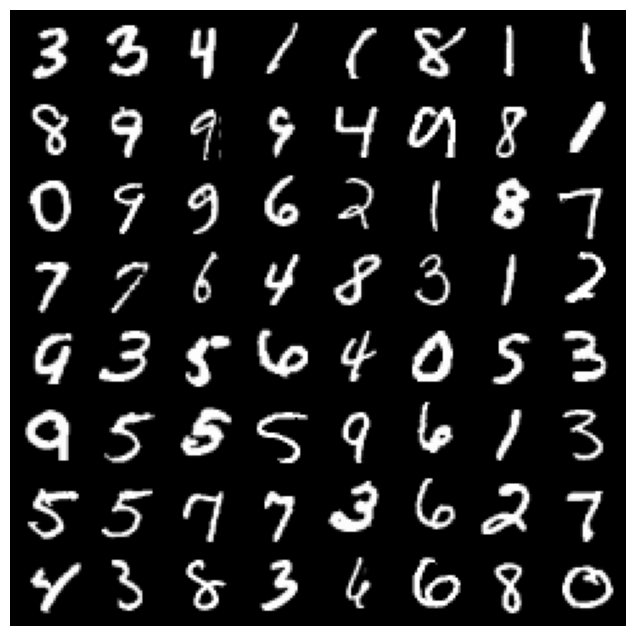

Shape of the batch: torch.Size([64, 784])


In [5]:
import seaborn as sns
sns.set(style='whitegrid')

for epoch in range(5):
    for data in dataloader:
        imgs, _ = data
        imgs = imgs.view(imgs.size(0), -1)
        # draw the images
        plt.figure(figsize=(8, 8))
        plt.axis('off')
        plt.imshow(np.transpose(torchvision.utils.make_grid(imgs.view(-1, 1, 28, 28), nrow=8, padding=2, normalize=True).cpu(), (1, 2, 0)))
        plt.show()
        print(f"Shape of the batch: {imgs.shape}")
        break
    break

In [13]:
class Autoencoder(nn.Module):
    def __init__(self):
        super(Autoencoder, self).__init__()
        # TODO: Define the encoder and decoder networks
        # The encoder should have the following architecture:
        # Input layer: Linear 28*28 x 128
        # Relu activation
        # Linear 128 x 64
        # Relu activation
        # Linear 64 x 12

        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 12)
        )

        # The decoder should have the following architecture:
        # Input layer: Linear 12 x 64
        # Relu activation
        # Linear 64 x 128
        # Relu activation
        # Linear 128 x 28*28
        # Sigmoid activation


        self.decoder = nn.Sequential(
            nn.Linear(12, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 28*28),
            nn.Sigmoid() 
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)

        return decoded

Training Epoch 1/5: 100%|██████████| 938/938 [00:06<00:00, 138.31it/s]


Epoch [1/5], Loss: 0.0467


Overall Training Progress:  20%|██        | 1/5 [00:07<00:30,  7.56s/it]

Validation Loss: 0.0294
Epoch [1/5], Validation Loss: 0.0294


Training Epoch 2/5: 100%|██████████| 938/938 [00:06<00:00, 134.30it/s]


...

Validation Loss: 0.0187
Epoch [4/5], Validation Loss: 0.0187


Training Epoch 5/5: 100%|██████████| 938/938 [00:06<00:00, 135.02it/s]


Epoch [5/5], Loss: 0.0186


Overall Training Progress: 100%|██████████| 5/5 [00:38<00:00,  7.79s/it]

Validation Loss: 0.0178
Epoch [5/5], Validation Loss: 0.0178
Training complete.


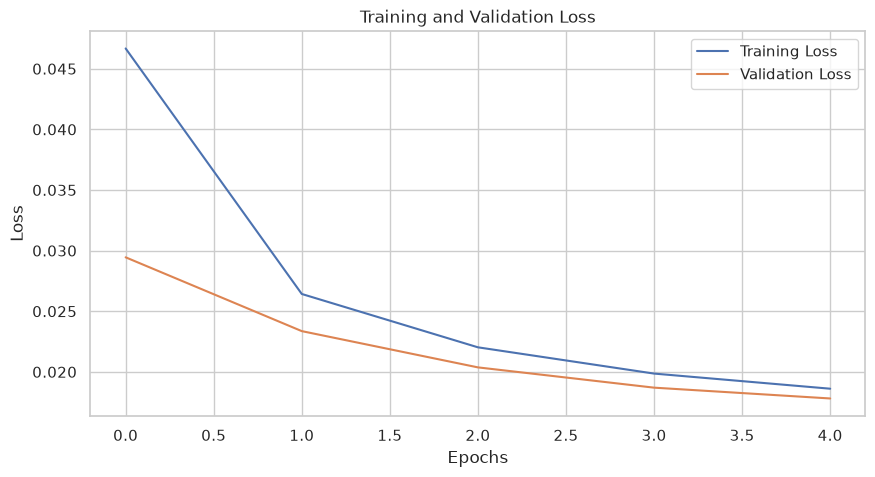

In [ ]:
from tqdm import tqdm

def train_autoencoder(model, dataloader, validation_dataloader, num_epochs=20, learning_rate=1e-3):

    # TODO: define the optimisation criterion (loss) as MSELoss and the optimiser as Adam
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    history = {'loss': [], 'running_loss': [], 'val_loss': []}

    for epoch in tqdm(range(num_epochs), desc="Overall Training Progress"):
        
        #remeber this flag during training
        # it enables things like dropout and batchnorm
        model.train()
        running_loss = 0.0

        for data in tqdm(dataloader, desc=f"Training Epoch {epoch+1}/{num_epochs}"):
            imgs, _ = data
            imgs = imgs.view(imgs.size(0), -1)

            # TODO: implement the training step
            # you need to zero the gradients, perform the forward pass, compute the loss,
            # perform the backward pass, and update the weights.
            # loss should be saved in a tensor named loss
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, imgs)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            history['running_loss'].append(loss.item())

        avg_loss = running_loss / len(dataloader)

        history['loss'].append(avg_loss)
        print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}")

        # TODO: calculate the validation loss after each epoch !
        avg_val_loss = validate_autoencoder(model, validation_dataloader)
        history['val_loss'].append(avg_val_loss)
        print(f"Epoch [{epoch+1}/{num_epochs}], Validation Loss: {avg_val_loss:.4f}")
    print("Training complete.")

    return history

def validate_autoencoder(model, validation_dataloader):
    #remember this flag: it disables things like dropout and batchnorm
    model.eval()

    # TODO: define the loss criterion as MSELoss
    criterion = nn.MSELoss()
    val_loss = 0.0

    # no_grad context is used to disable gradient calculation
    with torch.no_grad():
        for data in validation_dataloader:
            imgs, _ = data
            imgs = imgs.view(imgs.size(0), -1)
             # TODO : implement the validation step
             # you need to perform the forward pass and compute the loss
             # loss should be saved in a tensor named loss
            outputs = model(imgs)
            loss = criterion(outputs, imgs)
            val_loss += loss.item()

    avg_val_loss = val_loss / len(validation_dataloader)
    print(f"Validation Loss: {avg_val_loss:.4f}")
    return avg_val_loss

autoencoder = Autoencoder()

# DO NOT CHANGE BELOW

history = train_autoencoder(autoencoder, dataloader, validation_dataloader, num_epochs=5, learning_rate=1e-3)
plt.figure(figsize=(10, 5))
plt.plot(history['loss'], label='Training Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')
plt.show()

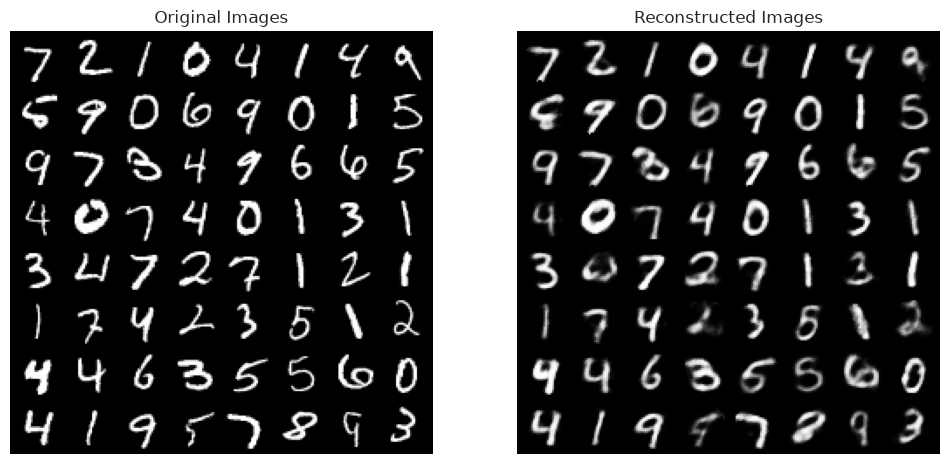

In [22]:
# DO NOT CHANGE THE FUNCTIONS BELOW

def inference_autoencoder(model, images):
    model.eval()
    with torch.no_grad():
        images = images.view(images.size(0), -1)
        outputs = model(images)
    return outputs 
# Get a batch of validation images
dataiter = iter(validation_dataloader)
images, labels = next(dataiter)
# Reconstruct the images using the autoencoder
reconstructed = inference_autoencoder(autoencoder, images)



# Display original and reconstructed images
plt.figure(figsize=(12, 6))
# Original images
plt.subplot(1, 2, 1)
plt.title('Original Images')
plt.axis('off')
plt.imshow(np.transpose(torchvision.utils.make_grid(images.view(-1, 1, 28, 28), nrow=8, padding=2, normalize=True).cpu(), (1, 2, 0)))
# Reconstructed images
plt.subplot(1, 2, 2)
plt.title('Reconstructed Images')
plt.axis('off')
plt.imshow(np.transpose(torchvision.utils.make_grid(reconstructed.view(-1, 1, 28, 28), nrow=8, padding=2, normalize=True).cpu(), (1, 2, 0)))
plt.show() 

## Part 2: Autoencoder with a weird twist !! (25 points)

In this task, you will implement the training and validation loops for an autoencoder model using PyTorch. The autoencoder will be trained to reconstruct images from the MNIST dataset. You will need to define the loss function and the optimizer, and implement the training and validation steps.

The twist is that you will need to also add a seperate classification head to the autoencoder, and train it to classify the digits as well. The classification head will take the latent representation from the encoder and output a probability distribution over the 10 classes (digits 0-9).

The architecture of the autoencoder with the classification head is as follows:

```
Input Layer --> Encoder --> Latent Space --> Decoder --> Output Layer
                                      |
                                      --> Classifier --> Class Probabilities
```


In [ ]:
#add a seperate head to classify the digits based on the encoded representation

class AutoencoderWithClassifier(nn.Module):
    def __init__(self):
        super(AutoencoderWithClassifier, self).__init__()
        #TODO: Define the encoder, decoder and classifier networks
        # The encoder should have the following architecture:
        # Input layer: Linear 28*28 x 128
        # Relu activation
        # Linear 128 x 64
        # Relu activation
        # Linear 64 x 12
        self.encoder = nn.Sequential(

        )

        # the decoder should be the same as above
        self.decoder = nn.Sequential(

        )

        #the classifier should be a simple feedforward network with the following architecture:
        # Input layer: Linear 12 x 32
        # Relu activation
        # Linear 32 x 10
        # Softmax activation (use nn.CrossEntropyLoss in the training which applies softmax internally)
        self.classifier = nn.Sequential(
        )

    def forward(self, x):
        # TODO : Define the forward pass, it should return both the reconstructed image and the class logits
        return decoded, class_logits


In [ ]:
def train_autoencoder_with_classifier(model, dataloader, validation_dataloader, num_epochs=20, learning_rate=1e-3):
    reconstruction_criterion = nn.MSELoss()

    #TODO: define the classification criterion as CrossEntropyLoss and the optimiser as Adam
    classification_criterion = 
    optimizer = 

    history = {'reconstruction_loss': [], 'classification_loss': [], 'val_reconstruction_loss': [], 'val_classification_loss': []}
    for epoch in tqdm(range(num_epochs), desc="Overall Training Progress"):
        model.train()
        running_reconstruction_loss = 0.0
        running_classification_loss = 0.0
        for data in tqdm(dataloader, desc=f"Training Epoch {epoch+1}/{num_epochs}"):
            imgs, labels = data
            imgs = imgs.view(imgs.size(0), -1)

            # Forward pass
            reconstructed, class_logits = model(imgs)

            # TODO: compute the reconstruction loss and classification loss
            reconstruction_loss = 
            classification_loss = 
            total_loss = reconstruction_loss + classification_loss
            # TODO: Backward pass and optimization

            running_reconstruction_loss += reconstruction_loss.item()
            running_classification_loss += classification_loss.item()
        avg_reconstruction_loss = running_reconstruction_loss / len(dataloader)
        avg_classification_loss = running_classification_loss / len(dataloader)
        history['reconstruction_loss'].append(avg_reconstruction_loss)
        history['classification_loss'].append(avg_classification_loss)
        print(f"Epoch [{epoch+1}/{num_epochs}], Reconstruction Loss: {avg_reconstruction_loss:.4f}, Classification Loss: {avg_classification_loss:.4f}")
        avg_val_reconstruction_loss, avg_val_classification_loss = validate_autoencoder_with_classifier(model, validation_dataloader)
        history['val_reconstruction_loss'].append(avg_val_reconstruction_loss)
        history['val_classification_loss'].append(avg_val_classification_loss)
        print(f"Epoch [{epoch+1}/{num_epochs}], Validation Reconstruction Loss: {avg_val_reconstruction_loss:.4f}, Validation Classification Loss: {avg_val_classification_loss:.4f}")
    print("Training complete.")
    return history

def validate_autoencoder_with_classifier(model, validation_dataloader):
    model.eval()
    reconstruction_criterion = nn.MSELoss()
    classification_criterion = nn.CrossEntropyLoss()
    val_reconstruction_loss = 0.0
    val_classification_loss = 0.0
    with torch.no_grad():
        for data in validation_dataloader:
            imgs, labels = data
            imgs = imgs.view(imgs.size(0), -1)
            reconstructed, class_logits = model(imgs)
            reconstruction_loss = reconstruction_criterion(reconstructed, imgs)
            classification_loss = classification_criterion(class_logits, labels)
            val_reconstruction_loss += reconstruction_loss.item()
            val_classification_loss += classification_loss.item()
    avg_val_reconstruction_loss = val_reconstruction_loss / len(validation_dataloader)
    avg_val_classification_loss = val_classification_loss / len(validation_dataloader)
    print(f"Validation Reconstruction Loss: {avg_val_reconstruction_loss:.4f}, Validation Classification Loss: {avg_val_classification_loss:.4f}")
    return avg_val_reconstruction_loss, avg_val_classification_loss

autoencoder_with_classifier = AutoencoderWithClassifier()
history_with_classifier = train_autoencoder_with_classifier(autoencoder_with_classifier, dataloader, validation_dataloader, num_epochs=5, learning_rate=1e-3)


In [ ]:
# DO NOT CHANGE THE FUNCTION BELOW

def visualize_reconstructions_with_labels(model, dataloader):
    model.eval()
    dataiter = iter(dataloader)
    images, labels = next(dataiter)
    with torch.no_grad():
        images_flat = images.view(images.size(0), -1)
        reconstructed, class_logits = model(images_flat)
        _, predicted_labels = torch.max(class_logits, 1)

    plt.figure(figsize=(12, 6))
    # Original images
    plt.subplot(1, 2, 1)
    plt.title('Original Images with Labels')
    plt.axis('off')
    grid_img = torchvision.utils.make_grid(images.view(-1, 1, 28, 28), nrow=8, padding=2, normalize=True).cpu()
    plt.imshow(np.transpose(grid_img, (1, 2, 0)))
    for i in range(len(labels)):
        plt.text((i % 8) * (28 + 2) + 14, (i // 8) * (28 + 2) + 28 + 10, str(labels[i].item()), color='red', fontsize=12, ha='center')

    # Reconstructed images
    plt.subplot(1, 2, 2)
    plt.title('Reconstructed Images with Predicted Labels')
    plt.axis('off')
    grid_reconstructed = torchvision.utils.make_grid(reconstructed.view(-1, 1, 28, 28), nrow=8, padding=2, normalize=True).cpu()
    plt.imshow(np.transpose(grid_reconstructed, (1, 2, 0)))
    for i in range(len(predicted_labels)):
        plt.text((i % 8) * (28 + 2) + 14, (i // 8) * (28 + 2) + 28 + 10, str(predicted_labels[i].item()), color='blue', fontsize=12, ha='center')

    plt.show()
visualize_reconstructions_with_labels(autoencoder_with_classifier, validation_dataloader)

# Part 3: Questions (10 points)

Answer the following questions as elaborately as possible:

**Question 1**: What is the purpose of the latent space in an autoencoder?

**Question 2**: How does the choice of loss function affect the training of an autoencoder?

**Question 3**: Does training an autoencoder with a classification head improve the quality of the learned representations? Why or why not?


# Part 4: Another twist to the autoencoder (extra credit: 10 points)

Add the following modifications to the autoencoder:
1. **Classification Head**: Add a classification head to the autoencoder that takes the final (NOT THE LATENT) encoded representation and outputs class probabilities for the 10 classes (digits 0-9).
2. **Loss Function**: Use a combined loss function that includes both the reconstruction loss (MSELoss) and the classification loss (CrossEntropyLoss). (like in the previous part)
3. **Training Loop**: Implement the training loop to optimize both the reconstruction and classification losses.




# Part 5: Advanced Autoencoder (hard mode, 20 points)

In this part, you will build a **denoising + sparse autoencoder** and compare it with your previous models.

## Requirements

1. Add Gaussian noise to each input sample during training only.
2. Add a sparsity regularization term on the latent vector:
   - `L_total = L_reconstruction + alpha * mean(|z|)`
3. Use a larger latent space than before (for example 24 or 32) and justify your choice.
4. Track and plot:
   - Training reconstruction loss
   - Validation reconstruction loss
   - Validation sparsity penalty
5. Compare the visual reconstruction quality against Part 1 and Part 2.

## Expected discussion

After training, briefly answer:
- When does denoising help reconstruction quality?
- What is the tradeoff between sparsity and reconstruction fidelity?
- Does a larger latent size always help?


In [ ]:
# Part 5 starter code (complete the TODOs)

class DenoisingSparseAutoencoder(nn.Module):
    def __init__(self, latent_dim=24):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 28 * 28),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat, z


def add_gaussian_noise(x, noise_std=0.2):
    """Add zero-mean Gaussian noise and clip to [0, 1]."""
    noise = torch.randn_like(x) * noise_std
    return torch.clamp(x + noise, 0.0, 1.0)


def train_denoising_sparse_autoencoder(
    model,
    dataloader,
    validation_dataloader,
    num_epochs=10,
    learning_rate=1e-3,
    alpha=1e-3,
    noise_std=0.2,
):
    reconstruction_criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    history = {
        "train_reconstruction_loss": [],
        "val_reconstruction_loss": [],
        "val_sparsity_penalty": [],
    }

    for epoch in range(num_epochs):
        model.train()
        total_train_recon = 0.0

        for images, _ in dataloader:
            images_flat = images.view(images.size(0), -1)
            noisy_images = add_gaussian_noise(images_flat, noise_std=noise_std)

            # TODO: full training step
            # 1) zero gradients
            # 2) forward pass on noisy images
            # 3) compute reconstruction loss against clean images
            # 4) compute sparsity penalty = mean(abs(z))
            # 5) total loss = recon + alpha * sparsity
            # 6) backward + optimizer step

            optimizer.zero_grad()

            # write your code here.

            total_train_recon += recon_loss.item() * images.size(0)

        avg_train_recon = total_train_recon / len(dataloader.dataset)

        # Validation
        model.eval()
        total_val_recon = 0.0
        total_val_sparse = 0.0

        with torch.no_grad():
            for images, _ in validation_dataloader:
                images_flat = images.view(images.size(0), -1)
                reconstructed, z = model(images_flat)
                recon_loss = reconstruction_criterion(reconstructed, images_flat)
                sparsity_penalty = torch.mean(torch.abs(z))

                total_val_recon += recon_loss.item() * images.size(0)
                total_val_sparse += sparsity_penalty.item() * images.size(0)

        avg_val_recon = total_val_recon / len(validation_dataloader.dataset)
        avg_val_sparse = total_val_sparse / len(validation_dataloader.dataset)

        history["train_reconstruction_loss"].append(avg_train_recon)
        history["val_reconstruction_loss"].append(avg_val_recon)
        history["val_sparsity_penalty"].append(avg_val_sparse)

        print(
            f"Epoch [{epoch + 1}/{num_epochs}] | "
            f"Train Recon: {avg_train_recon:.6f} | "
            f"Val Recon: {avg_val_recon:.6f} | "
            f"Val Sparse: {avg_val_sparse:.6f}"
        )

    return history


# Optional run
# advanced_autoencoder = DenoisingSparseAutoencoder(latent_dim=24)
# advanced_history = train_denoising_sparse_autoencoder(
#     advanced_autoencoder,
#     dataloader,
#     validation_dataloader,
#     num_epochs=5,
#     learning_rate=1e-3,
#     alpha=1e-3,
#     noise_std=0.2,
# )


# Part 6: Skip-gram Word2Vec from scratch (20 points total)

In this part, you will implement **Skip-gram Word2Vec** in two versions.

## Goal

Learn embeddings so that words appearing in similar contexts have similar vectors.

## Shared setup (for both subparts)

1. Build a simple text preprocessing pipeline:
   - lowercase
   - remove punctuation (optional but recommended)
   - split into tokens
2. Build vocabulary dictionaries:
   - `word_to_ix`
   - `ix_to_word`
3. Create skip-gram `(center_word, context_word)` training pairs using a context window.
4. Implement a `Dataset`/`DataLoader` for pairs.

## Part 6A: Full Softmax (10 points)

Implement skip-gram with a full-vocabulary softmax objective.

## Part 6B: Negative Sampling (10 points)

Implement skip-gram with negative sampling and compare training behavior against Part 6A.

Use small dimensions first (`embedding_dim=50`) to debug quickly.


In [ ]:
# Part 6 starter code (TODO assignment, no full solution)

import re
from collections import Counter
from torch.utils.data import Dataset, DataLoader


# Load an actual text dataset (AG News)
# If needed: pip install datasets
from datasets import load_dataset


def load_ag_news_corpus(max_train_samples=5000):
    ds = load_dataset("ag_news", split=f"train[:{max_train_samples}]")
    texts = [row["text"] for row in ds]
    return "\n".join(texts)


text_corpus = load_ag_news_corpus(max_train_samples=5000)
print(f"Loaded AG News corpus with {len(text_corpus.split())} tokens (before preprocessing)")


def preprocess_text(text):
    # TODO 1: improve preprocessing if needed
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = text.split()
    return tokens


def build_vocab(tokens, min_freq=1):
    # TODO 2: create word_counts, vocab, word_to_ix, ix_to_word
    pass


def build_skipgram_pairs(tokens, word_to_ix, window_size=2):
    # TODO 3: build (center, context) pairs
    pass


class SkipGramDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        center, context = self.pairs[idx]
        return torch.tensor(center, dtype=torch.long), torch.tensor(context, dtype=torch.long)


# Shared setup
tokens = preprocess_text(text_corpus)
word_counts, vocab, word_to_ix, ix_to_word = build_vocab(tokens, min_freq=1)
pairs = build_skipgram_pairs(tokens, word_to_ix, window_size=2)
dataset = SkipGramDataset(pairs)
dataloader = DataLoader(dataset, batch_size=16, shuffle=True)
print(f"Vocabulary size: {len(vocab)} | Number of pairs: {len(pairs)}")


# -----------------------------
# Part 6A: Full Softmax (10 pts)
# -----------------------------
class SkipGramSoftmax(nn.Module):
    def __init__(self, vocab_size, embedding_dim):
        super().__init__()
        self.in_embeddings = nn.Embedding(vocab_size, embedding_dim)
        self.out_linear = nn.Linear(embedding_dim, vocab_size)

    def forward(self, center_words):
        # TODO 4: return logits of shape [B, vocab_size]
        # Hint: center -> embedding -> linear projection to vocab size
        raise NotImplementedError("TODO: implement softmax forward pass")


def train_skipgram_softmax(model, dataloader, num_epochs=10, learning_rate=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    for epoch in range(num_epochs):
        total_loss = 0.0
        for center_batch, context_batch in dataloader:
            # TODO 5: complete training step for full softmax
            # 1) zero gradients
            # 2) logits = model(center_batch)
            # 3) loss = criterion(logits, context_batch)
            # 4) backward + optimizer step
            # 5) accumulate total_loss
            raise NotImplementedError("TODO: implement softmax training step")

        avg_loss = total_loss / len(dataloader.dataset)
        print(f"[Softmax] Epoch {epoch + 1}/{num_epochs} - Loss: {avg_loss:.4f}")


# -----------------------------------
# Part 6B: Negative Sampling (10 pts)
# -----------------------------------
class SkipGramNegativeSampling(nn.Module):
    def __init__(self, vocab_size, embedding_dim):
        super().__init__()
        self.target_embeddings = nn.Embedding(vocab_size, embedding_dim)
        self.context_embeddings = nn.Embedding(vocab_size, embedding_dim)

        nn.init.xavier_uniform_(self.target_embeddings.weight)
        nn.init.xavier_uniform_(self.context_embeddings.weight)

    def forward(self, center_words, pos_context_words, neg_context_words):
        # TODO 6: implement negative sampling loss
        # Expected shapes:
        # center_words: [B], pos_context_words: [B], neg_context_words: [B, K]
        # Hint:
        # - positive term: log sigma(v_c . v_o)
        # - negative term: sum_k log sigma(-v_c . v_nk)
        raise NotImplementedError("TODO: implement negative sampling loss")


def sample_negative(batch_size, num_negatives, dist):
    # TODO 7: sample negative word indices using the given distribution
    # Output shape should be [batch_size, num_negatives]
    raise NotImplementedError("TODO: implement negative sampling sampler")


def train_skipgram_negative_sampling(
    model,
    dataloader,
    neg_sampling_dist,
    num_negatives=5,
    num_epochs=10,
    learning_rate=1e-3,
):
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    for epoch in range(num_epochs):
        total_loss = 0.0
        for center_batch, context_batch in dataloader:
            batch_size = center_batch.size(0)
            negative_batch = sample_negative(batch_size, num_negatives, neg_sampling_dist)

            # TODO 8: complete training step for negative sampling
            # 1) zero gradients
            # 2) loss = model(center_batch, context_batch, negative_batch)
            # 3) backward + optimizer step
            # 4) accumulate total_loss
            raise NotImplementedError("TODO: implement negative sampling training step")

        avg_loss = total_loss / len(dataloader.dataset)
        print(f"[NegSampling] Epoch {epoch + 1}/{num_epochs} - Loss: {avg_loss:.4f}")


# Build unigram distribution^(3/4) for negative sampling
unigram = torch.tensor([word_counts[ix_to_word[i]] for i in range(len(vocab))], dtype=torch.float)
neg_sampling_dist = unigram.pow(0.75)
neg_sampling_dist = neg_sampling_dist / neg_sampling_dist.sum()


# TODO 9: run both models and compare training curves
# Example:
# softmax_model = SkipGramSoftmax(vocab_size=len(vocab), embedding_dim=50)
# train_skipgram_softmax(softmax_model, dataloader, num_epochs=20, learning_rate=1e-2)
#
# neg_model = SkipGramNegativeSampling(vocab_size=len(vocab), embedding_dim=50)
# train_skipgram_negative_sampling(
#     neg_model,
#     dataloader,
#     neg_sampling_dist,
#     num_negatives=5,
#     num_epochs=20,
#     learning_rate=1e-2,
# )


# TODO 10: write helper to inspect nearest neighbors and compare both variants


## Part 6 Questions (included in Part 6 points)

1. Why do we use two embedding matrices in skip-gram training?
2. Why is negative sampling computationally more efficient than full softmax for large vocabularies?
3. How does context window size affect the type of semantic/syntactic relationships captured?
4. Replace the toy corpus with a larger Armenian or English corpus and compare nearest-neighbor quality.
5. (Bonus) Implement cosine-similarity-based nearest neighbors and compare against raw dot product.
